# Mayoristas v3 -- punto de partida

`upt` (unidades por ticket) en v1/v2 suma `unidades` de TODOS los productos de un ticket sin importar `unidad_medida`. Mezcla KILOS, LITROS, Unid, Blis, Pack, Metros y Ramo como si fueran la misma cosa. Un cliente que compra 130 KILOS y 697 Unid en el mismo ticket queda con upt=827, que no representa ningun comportamiento real de compra.

Antes de rediseñar la metodologia, primero hay que ver la magnitud del problema:
1. Boxplot de unidades y venta por ticket, tal como lo consume v2 hoy (todas las unidades de medida mezcladas).
2. El mismo boxplot, desagregado por `unidad_medida` -- para ver si de verdad son escalas incompatibles.

C1 — ¿Compra mucho, en promedio?
Es el promedio de unidades que compra el cliente cada vez que viene (kilos por ticket, o unidades sueltas por ticket, etc. -- por separado para Unid/KILOS/LITROS/Pack). Se compara contra el resto de los clientes: si su promedio está entre el 25% que más compra en esa unidad, cumple C1.

C2 — ¿Compra grande de forma consistente, no una sola vez?
Primero se define qué es una "compra grande" para cada unidad (un corte estadístico sobre todos los tickets). Después se mide qué porcentaje de las VECES que el cliente vino fueron compras grandes. Si al menos 4 de cada 10 visitas fueron grandes, cumple C2. La diferencia con C1: C1 es el promedio (una sola compra gigante lo puede inflar), C2 mide si es un patrón repetido.

C3 — ¿Gasta mucha plata por visita?
Lo mismo que C1 pero en guaraníes en vez de unidades, y sin separar por tipo de producto -- la plata es una sola moneda común a todo lo que compra. Si su gasto promedio por visita está entre el 25% que más gasta, cumple C3.

Cómo se combina: el cliente suma 1 punto por cada criterio que cumple (0 a 3). 3 = Alto, 2 = Medio, 1 = Potencial, 0 = Minorista.

El dato que justifica todo el proyecto, si preguntan "¿y esto por qué es distinto de antes?": antes C1 y C2 sumaban kilos y unidades sueltas como si fueran la misma cosa (mezclar 100 kilos con 100 latitas). Ahora se mide cada unidad por separado, y alcanza con destacarse en cualquiera de las 4 -- un cliente que compra mucho en Unid ya califica, no hace falta que también compre mucho en KILOS.



In [24]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))

from conexion_bd import conexion_bd

pd.set_option("display.float_format", "{:,.2f}".format)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 11,
})

## Carga

Parte de `intermediate.int_ventas_12m` (modelo dbt real, no la vista legacy) --
ventana de 12 meses en meses cerrados + todas las exclusiones de negocio
(empresa, bolsa, egre/servi, cliente de test, productos excluidos, dedup
de `cliente_id` vía Fase 2) ya aplicadas ahí. Se suma `unidad_medida`
desde `staging.stg_productos` (el port dbt de `dbo.Productos`, ya con
`producto_id` normalizado), que `int_ventas_12m` no expone.

Nada de esto se reaplica en Python -- es exactamente el mismo principio
que ya usa `int_mayoristas_metricas_cliente.sql` ("las exclusiones que
el notebook aplicaba YA están cubiertas por `int_ventas_12m` -- no se
duplican acá").

In [25]:
SQL_VENTAS_CON_UNIDAD = """
SELECT
    v.fecha_venta,
    v.pdv_id,
    v.ticket_id,
    v.cliente_id_limpio,
    v.producto_id,
    p.unidad_medida,
    v.unidades,
    v.venta_gs
FROM intermediate.int_ventas_12m v
INNER JOIN staging.stg_productos p
    ON v.producto_id = p.producto_id
WHERE v.cliente_id_limpio IS NOT NULL
"""

with conexion_bd() as conn:
    ventas = pd.read_sql_query(SQL_VENTAS_CON_UNIDAD, conn)

ventas["fecha_venta"] = pd.to_datetime(ventas["fecha_venta"])
for col in ("cliente_id_limpio", "producto_id", "pdv_id", "ticket_id"):
    ventas[col] = ventas[col].astype(str)

print(f"Filas cargadas: {len(ventas):,}")
print(f"Clientes unicos: {ventas['cliente_id_limpio'].nunique():,}")
print(f"Unidades de medida presentes: {sorted(ventas['unidad_medida'].unique())}")
ventas.head()

C:\Users\adria\AppData\Local\Temp\ipykernel_99512\4148004579.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  ventas = pd.read_sql_query(SQL_VENTAS_CON_UNIDAD, conn)


Filas cargadas: 62,622,740
Clientes unicos: 398,433
Unidades de medida presentes: ['Blis', 'KILOS', 'LITROS', 'Metros', 'Pack', 'Ramo', 'Unid']


,fecha_venta,pdv_id,ticket_id,cliente_id_limpio,producto_id,unidad_medida,unidades,venta_gs
0,2025-08-01,3,15673870_003-021-0386804,1951831,0001426,Unid,1.00,"16,650.00"
1,2025-08-01,5,15673870_005-005-0137620,4847644,0002258,Unid,1.00,"16,350.00"
2,2025-08-01,5,15673870_005-025-0071371,5927913,0002258,Unid,1.00,"16,350.00"
3,2025-08-01,3,15673870_003-025-0244330,1923334,0070879,Unid,1.00,"11,550.00"
4,2025-08-01,6,15673870_006-013-0089070,3425613,0070879,Unid,2.00,"23,100.00"


## 1) Unidades y venta por ticket -- todas las unidades de medida mezcladas

Este es el insumo real de `upt` en v1/v2 hoy: suma de `unidades` por ticket sin discriminar que se esta sumando. Escala log en el eje Y -- la distribucion es muy asimetrica y sin log el boxplot queda ilegible.

In [26]:
por_ticket = (
    ventas.groupby("ticket_id", dropna=False)
    .agg(unidades=("unidades", "sum"), venta_gs=("venta_gs", "sum"))
    .reset_index()
)
por_ticket = por_ticket[por_ticket["unidades"] > 0]

print(f"Tickets: {len(por_ticket):,}")
por_ticket[["unidades", "venta_gs"]].describe()

Tickets: 4,679,668


,unidades,venta_gs
count,"4,679,668.00","4,679,668.00"
mean,19.12,"165,316.68"
std,28.90,"237,177.16"
min,0.00,5.00
25%,4.00,"36,380.00"
50%,10.15,"91,422.25"
75%,24.25,"207,658.56"
max,"12,200.00","48,553,400.00"


C:\Users\adria\AppData\Local\Temp\ipykernel_99512\3557704853.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(por_ticket["unidades"], vert=True, widths=0.4, **caja_estilo)
C:\Users\adria\AppData\Local\Temp\ipykernel_99512\3557704853.py:41: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(por_ticket["venta_gs"], vert=True, widths=0.4, **caja_estilo)


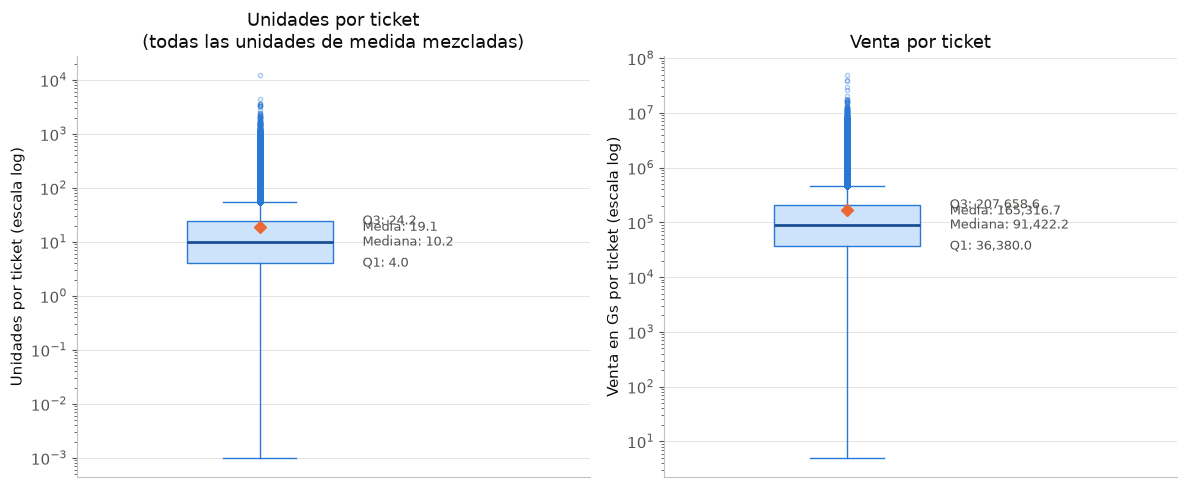

In [27]:
caja_estilo = dict(
    patch_artist=True,
    boxprops=dict(facecolor="#cde2fb", edgecolor="#2a78d6"),
    medianprops=dict(color="#184f95", linewidth=2),
    whiskerprops=dict(color="#2a78d6"),
    capprops=dict(color="#2a78d6"),
    flierprops=dict(markeredgecolor="#2a78d6", markersize=3, alpha=0.4),
    showmeans=True,
    meanprops=dict(marker="D", markerfacecolor="#eb6834", markeredgecolor="#eb6834", markersize=6),
)


def etiquetar_stats(ax, serie, x_texto=1.28):
    """Anota Q3/mediana/media/Q1 a la derecha de una caja única (boxplot
    de 1 sola serie) -- sin riesgo de amontonarse, por eso acá se ponen
    las 4, a diferencia del boxplot agrupado por unidad_medida más abajo."""
    stats = {
        "Q3": serie.quantile(0.75),
        "Mediana": serie.median(),
        "Media": serie.mean(),
        "Q1": serie.quantile(0.25),
    }
    for etiqueta, valor in stats.items():
        ax.annotate(
            f"{etiqueta}: {valor:,.1f}",
            xy=(x_texto, valor),
            fontsize=9, color="#52514e", va="center",
        )


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(por_ticket["unidades"], vert=True, widths=0.4, **caja_estilo)
axes[0].set_yscale("log")
axes[0].set_xticks([])
axes[0].set_xlim(0.5, 1.9)
axes[0].set_ylabel("Unidades por ticket (escala log)")
axes[0].set_title("Unidades por ticket\n(todas las unidades de medida mezcladas)")
etiquetar_stats(axes[0], por_ticket["unidades"])

axes[1].boxplot(por_ticket["venta_gs"], vert=True, widths=0.4, **caja_estilo)
axes[1].set_yscale("log")
axes[1].set_xticks([])
axes[1].set_xlim(0.5, 1.9)
axes[1].set_ylabel("Venta en Gs por ticket (escala log)")
axes[1].set_title("Venta por ticket")
etiquetar_stats(axes[1], por_ticket["venta_gs"])

plt.tight_layout()
plt.show()

## 2) Lo mismo, desagregado por `unidad_medida`

Grano cliente-ticket-unidad_medida -- si un ticket tiene lineas de KILOS y de Unid, aporta una fila a cada grupo. Un color fijo por unidad de medida (paleta categorica de `dataviz`, mismo orden en los dos paneles).

In [28]:
por_ticket_unidad = (
    ventas.groupby(["ticket_id", "unidad_medida"], dropna=False)
    .agg(unidades=("unidades", "sum"), venta_gs=("venta_gs", "sum"))
    .reset_index()
)
por_ticket_unidad = por_ticket_unidad[por_ticket_unidad["unidades"] > 0]

orden_unidades = sorted(por_ticket_unidad["unidad_medida"].unique())
paleta_categorica = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100",
    "#e87ba4", "#008300", "#4a3aa7", "#e34948",
]
paleta_por_unidad = dict(zip(orden_unidades, paleta_categorica))

por_ticket_unidad.groupby("unidad_medida")["unidades"].describe()

,count,mean,std,min,25%,50%,75%,max
unidad_medida,,,,,,,,
Blis,"6,995.00",1.38,1.51,0.20,1.00,1.00,1.00,100.00
KILOS,"3,362,792.00",5.71,6.99,0.00,1.44,3.49,7.56,"1,124.50"
LITROS,"173,778.00",2.66,2.45,0.06,1.00,2.00,3.00,112.00
Metros,"4,545.00",1.24,0.81,1.00,1.00,1.00,1.00,17.00
Pack,"51,430.00",1.44,1.82,0.14,1.00,1.00,1.00,126.00
Ramo,"39,500.00",1.99,2.55,1.00,1.00,1.00,2.00,165.00
Unid,"4,447,089.00",15.66,26.22,0.00,3.00,8.00,19.00,"12,100.00"


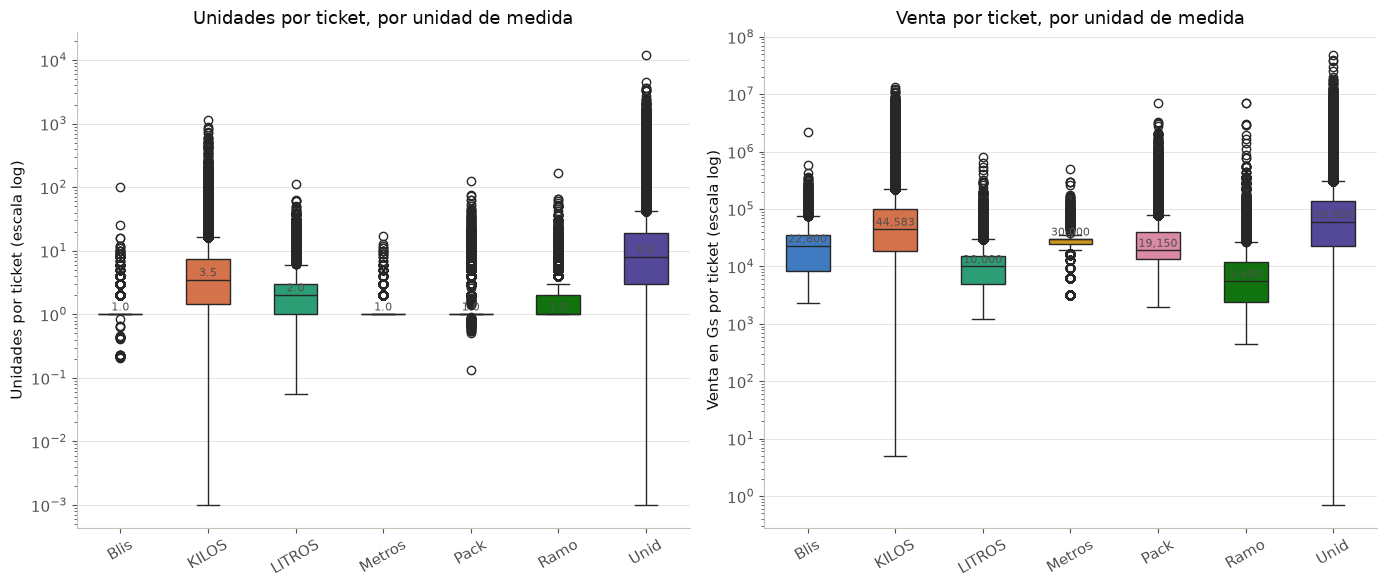

In [29]:
medianas_unidades = por_ticket_unidad.groupby("unidad_medida")["unidades"].median().reindex(orden_unidades)
medianas_venta = por_ticket_unidad.groupby("unidad_medida")["venta_gs"].median().reindex(orden_unidades)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=por_ticket_unidad, x="unidad_medida", y="unidades", order=orden_unidades,
    hue="unidad_medida", palette=paleta_por_unidad, legend=False, width=0.5, ax=axes[0],
)
axes[0].set_yscale("log")
axes[0].set_xlabel("")
axes[0].set_ylabel("Unidades por ticket (escala log)")
axes[0].set_title("Unidades por ticket, por unidad de medida")
axes[0].tick_params(axis="x", rotation=30)
for i, valor in enumerate(medianas_unidades):
    # Offset multiplicativo (no aditivo) -- estamos en escala log, un
    # desplazamiento fijo en unidades reales se ve distinto según la
    # magnitud de cada caja.
    axes[0].annotate(f"{valor:,.1f}", xy=(i, valor * 1.15), ha="center",
                      fontsize=8, color="#52514e")

sns.boxplot(
    data=por_ticket_unidad, x="unidad_medida", y="venta_gs", order=orden_unidades,
    hue="unidad_medida", palette=paleta_por_unidad, legend=False, width=0.5, ax=axes[1],
)
axes[1].set_yscale("log")
axes[1].set_xlabel("")
axes[1].set_ylabel("Venta en Gs por ticket (escala log)")
axes[1].set_title("Venta por ticket, por unidad de medida")
axes[1].tick_params(axis="x", rotation=30)
for i, valor in enumerate(medianas_venta):
    axes[1].annotate(f"{valor:,.0f}", xy=(i, valor * 1.15), ha="center",
                      fontsize=8, color="#52514e")

plt.tight_layout()
plt.show()

## 3) Top 10 tickets extremos -- chequeo de calidad de datos

Antes de usar los máximos de KILOS (1.124,5) y Unid (12.100), miramos si realmente cuadran esos valores, no alcanza con el resumen (min/max/cuartiles)
para descartar un ticket cargado mal.

In [30]:
from IPython.display import display

top10_kilos = (
    ventas[ventas["unidad_medida"] == "KILOS"]
    .groupby(["ticket_id", "cliente_id_limpio"], dropna=False)
    .agg(unidades=("unidades", "sum"), venta_gs=("venta_gs", "sum"))
    .reset_index()
    .sort_values("unidades", ascending=False)
    .head(10)
)

top10_unid = (
    ventas[ventas["unidad_medida"] == "Unid"]
    .groupby(["ticket_id", "cliente_id_limpio"], dropna=False)
    .agg(unidades=("unidades", "sum"), venta_gs=("venta_gs", "sum"))
    .reset_index()
    .sort_values("unidades", ascending=False)
    .head(10)
)

print("Top 10 tickets por unidades -- KILOS:")
display(top10_kilos)

print("\nTop 10 tickets por unidades -- Unid:")
display(top10_unid)

Top 10 tickets por unidades -- KILOS:


,ticket_id,cliente_id_limpio,unidades,venta_gs
653377,_003-010-0248326,1810675,"1,124.50","3,935,750.00"
1809742,_005-013-0311458,6388243,871.79,"2,179,475.00"
1462591,_005-002-0103077,741180,816.50,"6,420,578.00"
1462943,_005-002-0103661,741180,814.01,"7,242,276.00"
1463185,_005-002-0104065,741180,728.89,"7,330,830.50"
2885955,_006-011-0143628,1810675,701.60,"2,455,600.00"
591,15673870_003-004-0080951,80047227,610.81,"5,737,915.00"
1459838,_005-002-0098411,1810675,589.20,"1,885,440.00"
1632559,_005-009-0372852,1810675,587.60,"2,174,120.00"
868849,_003-014-0248824,1810675,578.80,"1,852,160.00"



Top 10 tickets por unidades -- Unid:


,ticket_id,cliente_id_limpio,unidades,venta_gs
244431,15673870_005-002-0087941,4375962,"12,100.00","15,004,700.00"
386,15673870_003-004-0080497,80013551,"4,478.00","29,248,200.00"
1933152,_005-002-0090914,80031782,"3,594.00","48,553,400.00"
1932473,_005-002-0090152,4375962,"3,577.00","4,425,250.00"
483526,15673870_006-001-0031457,2432217,"3,414.00","15,011,300.00"
2850585,_005-021-0185736,6167558,"3,367.00","1,363,700.00"
244449,15673870_005-002-0087960,4132638,"3,348.00","11,558,000.00"
1932648,_005-002-0090346,80035796,"3,324.00","39,167,900.00"
1933764,_005-002-0091629,80035796,"3,264.00","38,166,400.00"
3374989,_006-002-0088092,1438862,"2,736.00","6,840,000.00"


## 4) Prototipo: métrica corregida por `unidad_medida`

C1 y C2 (ver version 2) por unidad de medida: **Unid, KILOS, LITROS y Pack**.
Se agrega Pack porque bodegas/despensas, en general mayoristas, compran bebidas
por pack. Vale la pena notar que esto también se sostiene con los datos:
Pack tiene Q1=Q3=1 (IQR=0), así que el umbral Q3+1,5×IQR da exactamente
1, cualquier ticket con más de 1 pack ya queda marcado "grande", que es
un umbral razonable para esa unidad (la mayoría compra exactamente 1
pack por línea, más de eso ya es un salto real).
Blis/Metros/Ramo quedan afuera, sin variancia ni volumen que discriminar.

Metodología (mismo esquema que `analisis_mayoristas_v2.py`/
`int_mayoristas_metricas_cliente.sql`, corrigiendo qué alimenta C1/C2):
- **C1 (UPT alto)** y **C2 (% tickets grandes)**: se calculan por
  separado en cada uno de las 4 unidades de medida (umbral propio por unid. de med., no uno global mezclado como analisis anteriores).
  El cliente cumple el **criterio de mayorista** si lo cumple en
  CUALQUIER unidad de medida.
- **C3 (ventas totales)**: sigue global, sin separar por unid. medida -> ya está en
  guaraníes, común a todas las unidades (incluidas Blis/Metros/Ramo,
  que siguen sumando venta aunque no tengan C1/C2 propio).
- Puntaje 0-3, mismo mapeo a nivel que ya existe (3=Alto, 2=Medio,
  1=Potencial, 0=Minorista).

Todavía sin desagregar por sucursal (ambito GLOBAL/SL/R1/R2) -- se puede
sumar después con el mismo patrón que ya usa el dbt real, no cambia nada
de lo de abajo.

**Pipeline completo ya portado a dbt** -- el notebook de acá para abajo
ya no calcula nada de esto en Python, solo lee y valida:

```
mayoristas_v3_tickets_unidad         (cliente x ticket x unidad_medida -- C1/C2)
    -> mayoristas_v3_metricas_unidad (cliente x unidad_medida -- umbrales + c1/c2)
        -> mayoristas_v3_resumen     (cliente -- puntaje/nivel final)
        -> mayoristas_v3_umbrales    (1 fila x unidad_medida -- referencia)
```

`mayoristas_v3_tickets_unidad` es además la fuente directa de la página
de "historial de facturas" del tablero -- 1 fila por factura, con el
umbral y si contó como "grande" ya resueltos, sin bajar a línea de
producto ni agregar por mes (eso perdería el detalle de la factura
individual que el negocio necesita para explicar un caso puntual). Ver
`dbt_ahorrazo/models/marts/mayoristas/README.md` para el detalle
completo de la cadena.</cell id="2d8dcfd8">


In [ ]:
# umbrales: 1 fila por unidad_medida, ya calculada en dbt
# (marts_mayoristas.mayoristas_v3_umbrales) -- junta el umbral de
# ticket grande (Q3+3xIQR, a nivel ticket) y los umbrales de C1/C2
# (percentil 75 entre clientes, a nivel cliente). Referencia de
# metodología, no hace falta recalcular nada en Python.
SQL_UMBRALES = """
SELECT unidad_medida, umbral_ticket_grande, umbral_upt, umbral_pct
FROM marts_mayoristas.mayoristas_v3_umbrales
"""

with conexion_bd() as conn:
    umbrales = pd.read_sql_query(SQL_UMBRALES, conn).set_index("unidad_medida")

umbrales

In [ ]:
# metricas_por_unidad: C1/C2 por (cliente, unidad_medida), ya resueltos
# en dbt (marts_mayoristas.mayoristas_v3_metricas_unidad) -- upt,
# pct_tickets_grandes, los umbrales usados y los booleanos c1/c2, todo
# calculado en SQL. El notebook solo lee y valida, no recalcula.
SQL_METRICAS_UNIDAD = """
SELECT
    cliente_id_limpio,
    unidad_medida,
    tickets_unicos,
    upt,
    pct_tickets_grandes,
    umbral_upt,
    umbral_pct,
    c1_upt_alto,
    c2_pct_grandes_alto
FROM marts_mayoristas.mayoristas_v3_metricas_unidad
"""

with conexion_bd() as conn:
    metricas_por_unidad = pd.read_sql_query(SQL_METRICAS_UNIDAD, conn)

metricas_por_unidad["cliente_id_limpio"] = metricas_por_unidad["cliente_id_limpio"].astype(str)
metricas_por_unidad["c1_upt_alto"] = metricas_por_unidad["c1_upt_alto"].astype(bool)
metricas_por_unidad["c2_pct_grandes_alto"] = metricas_por_unidad["c2_pct_grandes_alto"].astype(bool)

print(f"Filas: {len(metricas_por_unidad):,}")

In [33]:
metricas_por_unidad.head()

,cliente_id_limpio,unidad_medida,tickets_unicos,upt,pct_tickets_grandes,umbral_upt,umbral_pct,c1_upt_alto,c2_pct_grandes_alto
0,0,KILOS,88,1.85,0.00,6.68,0.40,False,False
1,0,LITROS,1,1.00,0.00,3.00,0.40,False,False
2,0,Pack,2,2.00,0.50,1.00,0.40,True,True
3,0,Unid,296,2.30,0.00,19.50,0.40,False,False
4,00,KILOS,141,1.79,0.00,6.68,0.40,False,False


In [ ]:
# resultado: tabla final v3, ya calculada en dbt
# (marts_mayoristas.mayoristas_v3_resumen) -- C1/C2 combinados ("cumple
# en cualquier unidad"), C3 (venta promedio por ticket, global, todas
# las unidades) y puntaje/nivel_mayorista. El notebook ya no calcula
# nada de esto en Python, ni lo escribe a la base -- dbt es la fuente.
SQL_RESUMEN = """
SELECT
    cliente_id_limpio,
    venta_promedio_ticket,
    ventas_totales,
    c1_upt_alto,
    c2_pct_grandes_alto,
    c3_ventas_alto,
    umbral_c3,
    puntaje,
    nivel_mayorista
FROM marts_mayoristas.mayoristas_v3_resumen
"""

with conexion_bd() as conn:
    resultado = pd.read_sql_query(SQL_RESUMEN, conn)

resultado["cliente_id_limpio"] = resultado["cliente_id_limpio"].astype(str)
for col in ("c1_upt_alto", "c2_pct_grandes_alto", "c3_ventas_alto"):
    resultado[col] = resultado[col].astype(bool)
resultado["nivel_mayorista"] = pd.Categorical(
    resultado["nivel_mayorista"],
    categories=["Alto", "Medio", "Potencial", "Minorista"],
    ordered=True,
)

resultado["nivel_mayorista"].value_counts()

In [36]:
# Validación contra el cliente del ejemplo que arrancó esta investigación
# (2504462 -- salía "Alto" en v2 por mezclar KILOS y Unid en un solo upt).
resultado[resultado["cliente_id_limpio"] == "2504462"]

,cliente_id_limpio,venta_promedio_ticket,ventas_totales,c1_upt_alto,c2_pct_grandes_alto,c3_ventas_alto,puntaje,nivel_mayorista
74527,2504462,"853,047.00","5,971,329.00",True,True,True,3,Alto


In [ ]:
# Detalle por unidad de medida para el cliente de ejemplo -- de acá sale
# CUAL unidad (o unidades) dispara c1_upt_alto/c2_pct_grandes_alto, ya
# que "resultado" solo muestra el OR combinado, no el detalle.
CLIENTE_EJEMPLO = "2504462"

print("C1/C2 por unidad de medida:")
display(metricas_por_unidad[metricas_por_unidad["cliente_id_limpio"] == CLIENTE_EJEMPLO])

fila_cliente = resultado[resultado["cliente_id_limpio"] == CLIENTE_EJEMPLO]
print(f"\nC3 -- umbral (Q3 de venta_promedio_ticket del universo): {fila_cliente['umbral_c3'].iloc[0]:,.0f}")
display(fila_cliente)

## 6) Asimetría (skewness) y curtosis

Cuantifica lo que ya se veía en los boxplots: **asimetría** positiva alta
significa cola larga hacia la derecha (pocos tickets muy grandes empujan
la media muy por encima de la mediana -- coherente con que la media
siempre salió más alta que la mediana en las tablas de arriba).
**Curtosis** alta (excess kurtosis, 0 = como una normal) significa colas
más pesadas que una distribución normal -- más outliers extremos de los
que "deberían" aparecer. `pandas` calcula excess kurtosis por default
(`.kurt()`), no la curtosis de Pearson.

Primero la tabla con los números exactos, después los histogramas
(escala log en X, misma razón que en los boxplots -- sin log la
distribución no se puede ni mirar) con asimetría/curtosis anotadas en
cada panel.

In [38]:
forma_mezclada = pd.DataFrame({
    "unidades": [por_ticket["unidades"].skew(), por_ticket["unidades"].kurt()],
    "venta_gs": [por_ticket["venta_gs"].skew(), por_ticket["venta_gs"].kurt()],
}, index=["asimetria", "curtosis"])
print("Todas las unidades de medida mezcladas:")
display(forma_mezclada)


def asimetria(s):
    return s.skew()


def curtosis(s):
    # groupby no expone .kurt() como reduccion nativa (a diferencia de
    # .skew(), que si) -- por eso se envuelve en una funcion con nombre
    # en vez de pasar el string "kurt" a .agg().
    return s.kurt()


forma_por_unidad = (
    por_ticket_unidad.groupby("unidad_medida")[["unidades", "venta_gs"]]
    .agg([asimetria, curtosis])
)
print("\nPor unidad de medida:")
display(forma_por_unidad)

Todas las unidades de medida mezcladas:


,unidades,venta_gs
asimetria,27.82,11.21
curtosis,"7,454.51",916.79



Por unidad de medida:


unidades            venta_gs         
              asimetria  curtosis asimetria curtosis
unidad_medida                                       
Blis              41.38  2,605.30     23.97 1,182.63
KILOS              9.43    644.89     13.58   629.95
LITROS             4.23     54.02      8.96   358.38
Metros             7.28     81.92      5.68    84.65
Pack              17.97    701.40     21.66 1,142.08
Ramo              13.39    518.13     83.97 8,801.15
Unid              37.22 11,205.65     19.93 2,770.89

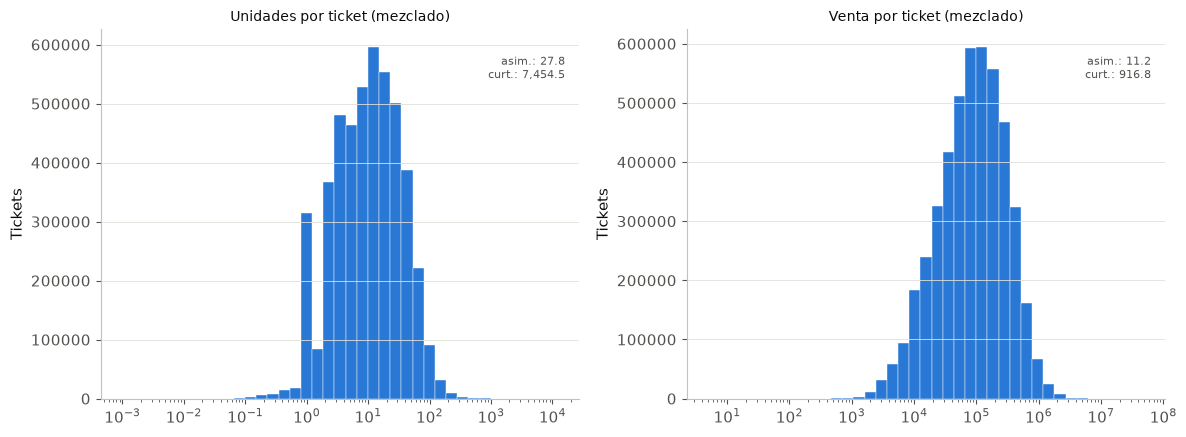

In [39]:
import numpy as np


def histograma_log(ax, serie, color, titulo):
    """Histograma con bins log-espaciados (geomspace, no linspace -- si
    no, con esta asimetria casi todos los bins quedan vacios) y
    asimetria/curtosis anotadas en la esquina, calculadas sobre los
    datos SIN transformar (la transformacion log es solo para que el
    ojo pueda ver la forma, no para el calculo de los estadisticos)."""
    datos = serie[serie > 0]
    bins = np.geomspace(datos.min(), datos.max(), 40)
    ax.hist(datos, bins=bins, color=color, edgecolor="white", linewidth=0.3)
    ax.set_xscale("log")
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel("Tickets")
    ax.text(
        0.97, 0.93, f"asim.: {datos.skew():,.1f}\ncurt.: {datos.kurt():,.1f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#52514e",
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
histograma_log(axes[0], por_ticket["unidades"], "#2a78d6", "Unidades por ticket (mezclado)")
histograma_log(axes[1], por_ticket["venta_gs"], "#2a78d6", "Venta por ticket (mezclado)")
plt.tight_layout()
plt.show()

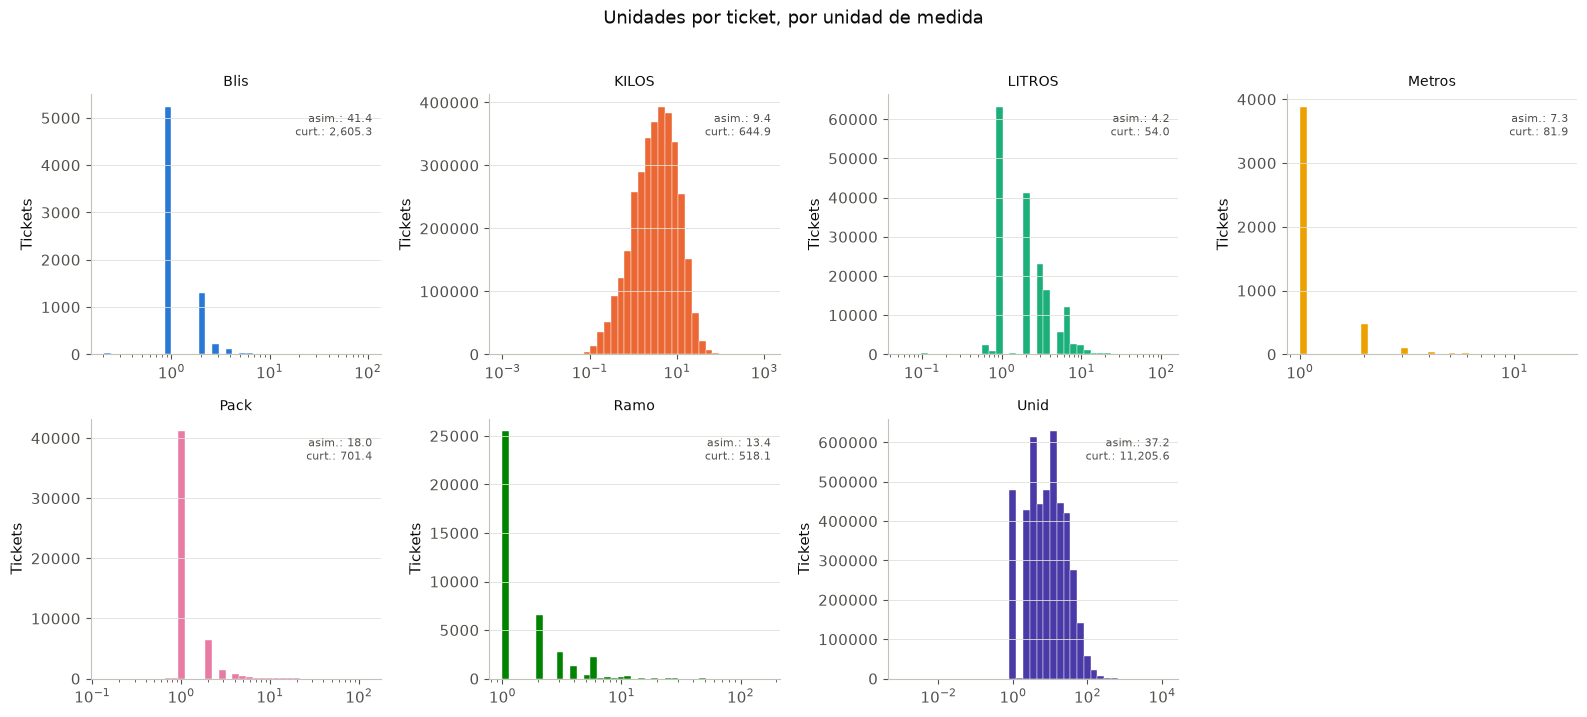

In [40]:
# Grilla 2x4, una unidad de medida por panel (7 unidades + 1 hueco).
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, unidad in enumerate(orden_unidades):
    serie = por_ticket_unidad.loc[por_ticket_unidad["unidad_medida"] == unidad, "unidades"]
    histograma_log(axes[i], serie, paleta_por_unidad[unidad], unidad)

for j in range(len(orden_unidades), len(axes)):
    axes[j].axis("off")

fig.suptitle("Unidades por ticket, por unidad de medida", y=1.02)
plt.tight_layout()
plt.show()

## 5) Verificar que dbt escribió bien

El notebook ya no escribe nada a la base -- las 4 tablas de v3
(`mayoristas_v3_tickets_unidad`, `mayoristas_v3_metricas_unidad`,
`mayoristas_v3_resumen`, `mayoristas_v3_umbrales`, todas en
`marts_mayoristas`) son modelos dbt, materializados corriendo
`dbt build --select mayoristas_v3_tickets_unidad+` (o el subset que
corresponda). Acá solo se chequea que las 4 existan y tengan filas --
sin esto, un `dbt build` fallido silencioso dejaría al notebook leyendo
tablas vacías o viejas sin ningún aviso.

In [ ]:
SQL_VERIFICAR = """
SELECT 'mayoristas_v3_tickets_unidad' AS tabla, COUNT(*) AS filas FROM marts_mayoristas.mayoristas_v3_tickets_unidad
UNION ALL
SELECT 'mayoristas_v3_metricas_unidad', COUNT(*) FROM marts_mayoristas.mayoristas_v3_metricas_unidad
UNION ALL
SELECT 'mayoristas_v3_resumen', COUNT(*) FROM marts_mayoristas.mayoristas_v3_resumen
UNION ALL
SELECT 'mayoristas_v3_umbrales', COUNT(*) FROM marts_mayoristas.mayoristas_v3_umbrales
"""

with conexion_bd() as conn:
    display(pd.read_sql_query(SQL_VERIFICAR, conn))